In [ ]:
# Google Colab : télécharger les données de cette séance / download this session's data
import os, urllib.request
BASE = "https://raw.githubusercontent.com/Marzoug-Nabil/Nabil/main/academic/teaching/fsci6222/materials/s08/"
for f in ['cancer_sein.csv', 'heart.csv']:
    os.makedirs('data', exist_ok=True)
    for dst in (f, os.path.join('data', f)):
        if not os.path.exists(dst):
            urllib.request.urlretrieve(BASE + f, dst)


# FSCI 6222 -- Analyse de donnees
# Seance 9 -- Introduction au Machine Learning
## Notebook de demonstration complet

**Universite de Moncton -- Faculte des sciences -- Ete 2026**

---

Ce notebook accompagne le cours de la seance 9 et met en pratique sur le dataset `cancer_sein.csv` **toutes les notions** du cours :

1. **Types de donnees et de problemes ML**
2. **Preparation des donnees** : encodage (Label/One-Hot), standardisation vs normalisation
3. **Train/test split** et stratification
4. **Validation croisee**
5. **Sur-apprentissage** et compromis biais-variance
6. **Hyperparameter tuning** avec GridSearchCV
7. **Data leakage** et Pipeline scikit-learn
8. **Cinq modeles** : KNN, Arbre, Random Forest, K-Means, Clustering hierarchique
9. **Synthese** et comparaison

Le dataset contient les caracteristiques cellulaires de 500 patientes avec un diagnostic (M = malin, B = benin).


---

## 1. Chargement et exploration des donnees


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
print('Environnement pret.')

Environnement pret.


In [3]:
# Chargement
df = pd.read_csv('cancer_sein.csv')
print(f'Dimensions : {df.shape}')
print(f'\nValeurs manquantes par colonne :')
print(df.isnull().sum())
print(f'\nDoublons : {df.duplicated().sum()}')
print(f'\nDistribution de la cible :')
print(df["diagnostic"].value_counts())
df.head()

Dimensions : (503, 10)

Valeurs manquantes par colonne :
id_patient           0
rayon_moyen          0
texture_moyenne      0
perimetre_moyen      0
surface_moyenne      0
lissage_moyen        0
compacite_moyenne    4
concavite_moyenne    0
symetrie_moyenne     4
diagnostic           0
dtype: int64

Doublons : 3

Distribution de la cible :
diagnostic
B    373
M    130
Name: count, dtype: int64


,id_patient,rayon_moyen,texture_moyenne,perimetre_moyen,surface_moyenne,lissage_moyen,compacite_moyenne,concavite_moyenne,symetrie_moyenne,diagnostic
0,1,12.19,21.62,79.3,464.8,0.0696,0.0771,0.0797,0.2261,B
1,2,9.14,20.33,63.4,228.3,0.0831,0.0892,0.0380,0.1996,B
2,3,11.30,24.72,80.0,374.4,0.1017,0.1672,0.2095,0.1959,M
3,4,13.75,15.75,90.2,639.9,0.0870,0.0615,0.1125,0.1315,B
4,5,13.78,22.05,83.6,597.5,0.0929,0.1153,0.2439,0.2191,M


### Identifier les types de donnees

**Avant tout traitement**, il faut comprendre la nature de chaque variable.


In [4]:
# Inspection des types
print('Types pandas :')
print(df.dtypes)

# Classification manuelle
print('\nClassification des variables :')
print('  - Identifiant     : id_patient (a exclure)')
print('  - 8 variables numeriques continues : rayon, texture, perimetre, surface, etc.')
print('  - 1 variable categorique nominale  : diagnostic (M / B) -> cible')


Types pandas :
id_patient             int64
rayon_moyen          float64
texture_moyenne      float64
perimetre_moyen      float64
surface_moyenne      float64
lissage_moyen        float64
compacite_moyenne    float64
concavite_moyenne    float64
symetrie_moyenne     float64
diagnostic               str
dtype: object

Classification des variables :
  - Identifiant     : id_patient (a exclure)
  - 8 variables numeriques continues : rayon, texture, perimetre, surface, etc.
  - 1 variable categorique nominale  : diagnostic (M / B) -> cible


**Type de probleme ML** : c'est un probleme de **classification binaire** supervisee (cible categorique a 2 classes M/B).


---

## 2. Nettoyage des donnees


In [5]:
df_clean = df.drop_duplicates().copy()

# Imputation des valeurs manquantes par la mediane
for col in ['compacite_moyenne', 'symetrie_moyenne']:
    if df_clean[col].isnull().any():
        median_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_val)
        print(f'  {col} : impute par la mediane {median_val:.4f}')

print(f'\nDimensions apres nettoyage : {df_clean.shape}')
print(f'NaN restants : {df_clean.isnull().sum().sum()}')

  compacite_moyenne : impute par la mediane 0.0875
  symetrie_moyenne : impute par la mediane 0.1858

Dimensions apres nettoyage : (500, 10)
NaN restants : 0


---

## 3. Encodage des variables categorielles

Le ML ne comprend que les **nombres**. Notre cible `diagnostic` est categorielle (M/B), il faut l'encoder.

**Deux methodes principales :**
- **Label Encoding** : remplace chaque categorie par un entier (utile pour les variables **ordinales**)
- **One-Hot Encoding** : cree une colonne binaire par categorie (pour les variables **nominales**)


### Label Encoding (cible binaire : approprie)


In [6]:
# Label encoding : M -> 1, B -> 0
le = LabelEncoder()
df_clean['malin'] = le.fit_transform(df_clean['diagnostic'])

print(f'Classes : {le.classes_}')
print(f'Mapping : {dict(zip(le.classes_, le.transform(le.classes_)))}')
df_clean[['diagnostic', 'malin']].head()

Classes : ['B' 'M']
Mapping : {'B': np.int64(0), 'M': np.int64(1)}


,diagnostic,malin
0,B,0
1,B,0
2,M,1
3,B,0
4,M,1


### Exemple comparatif sur une variable artificielle

Pour bien comprendre la difference, creons une variable categorielle nominale fictive :


In [7]:
# Exemple synthetique : ajouter une variable 'centre' avec 3 hopitaux
np.random.seed(42)
df_clean['centre'] = np.random.choice(['Hopital_A', 'Hopital_B', 'Hopital_C'], size=len(df_clean))

print('Variable centre (extrait) :')
print(df_clean[['centre']].head())

# Label encoding (PIEGE pour variable nominale)
df_label = df_clean[['centre']].copy()
df_label['centre_label'] = LabelEncoder().fit_transform(df_label['centre'])
print('\n--- Label Encoding ---')
print(df_label.head())
print('Probleme : Hopital_C=2 > Hopital_A=0 ?? Il n\'y a pourtant pas d\'ordre logique.')

Variable centre (extrait) :
      centre
0  Hopital_C
1  Hopital_A
2  Hopital_C
3  Hopital_C
4  Hopital_A

--- Label Encoding ---
      centre  centre_label
0  Hopital_C             2
1  Hopital_A             0
2  Hopital_C             2
3  Hopital_C             2
4  Hopital_A             0
Probleme : Hopital_C=2 > Hopital_A=0 ?? Il n'y a pourtant pas d'ordre logique.


In [8]:
# One-Hot Encoding (correct pour variable nominale)
df_onehot = pd.get_dummies(df_clean[['centre']], columns=['centre'], drop_first=False, dtype=int)
print('--- One-Hot Encoding ---')
print(df_onehot.head())
print('\nChaque categorie devient une colonne binaire. Aucun ordre fictif n\'est introduit.')

# On retire 'centre' pour la suite, c'etait juste pedagogique
df_clean = df_clean.drop(columns=['centre'])

--- One-Hot Encoding ---
   centre_Hopital_A  centre_Hopital_B  centre_Hopital_C
0                 0                 0                 1
1                 1                 0                 0
2                 0                 0                 1
3                 0                 0                 1
4                 1                 0                 0

Chaque categorie devient une colonne binaire. Aucun ordre fictif n'est introduit.


**A retenir :**
- Variable **ordinale** (S < M < L < XL) -> Label Encoding avec mapping ordonne
- Variable **nominale** (couleur, hopital) -> One-Hot Encoding
- Cible **binaire** -> Label Encoding (M=1, B=0) est approprie


---

## 4. Standardisation vs Normalisation

Les variables ont des **echelles tres differentes** : la surface va jusqu'a 2500 alors que le lissage est de l'ordre de 0,1.
Sans mise a l'echelle, les variables a grande amplitude **dominent les calculs** dans les algorithmes bases sur les distances (KNN, K-Means, SVM).


In [9]:
features = ['rayon_moyen', 'texture_moyenne', 'perimetre_moyen', 'surface_moyenne',
            'lissage_moyen', 'compacite_moyenne', 'concavite_moyenne', 'symetrie_moyenne']

X = df_clean[features]
y = df_clean['malin']

print('Echelles des variables (avant mise a l\'echelle) :')
print(X.describe().loc[['mean', 'std', 'min', 'max']].round(3))

Echelles des variables (avant mise a l'echelle) :
      rayon_moyen  texture_moyenne  perimetre_moyen  surface_moyenne  \
mean       13.215           18.587           85.805          578.363   
std         3.036            4.172           20.360          286.544   
min         7.090            9.000           43.000          120.000   
max        24.500           31.140          160.200         1864.300   

      lissage_moyen  compacite_moyenne  concavite_moyenne  symetrie_moyenne  
mean          0.094              0.094              0.076             0.185  
std           0.015              0.045              0.070             0.026  
min           0.050              0.020              0.000             0.107  
max           0.144              0.284              0.351             0.280  


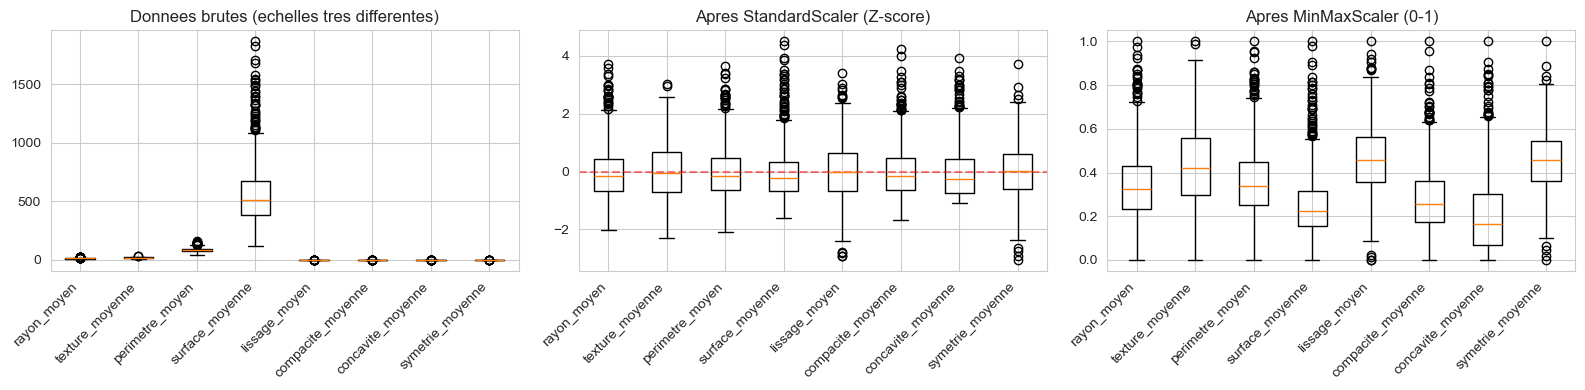

In [10]:
# Standardisation (Z-score) : moyenne=0, ecart-type=1
X_std = StandardScaler().fit_transform(X)
df_std = pd.DataFrame(X_std, columns=features)

# Normalisation Min-Max : valeurs dans [0, 1]
X_norm = MinMaxScaler().fit_transform(X)
df_norm = pd.DataFrame(X_norm, columns=features)

# Comparaison
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].boxplot([X[c] for c in features], labels=features)
axes[0].set_title('Donnees brutes (echelles tres differentes)')
axes[0].set_xticklabels(features, rotation=45, ha='right')

axes[1].boxplot([df_std[c] for c in features], labels=features)
axes[1].set_title('Apres StandardScaler (Z-score)')
axes[1].set_xticklabels(features, rotation=45, ha='right')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5)

axes[2].boxplot([df_norm[c] for c in features], labels=features)
axes[2].set_title('Apres MinMaxScaler (0-1)')
axes[2].set_xticklabels(features, rotation=45, ha='right')

plt.tight_layout()
plt.show()

**Observation :**
- Sur les donnees brutes, la **surface** ecrase visuellement toutes les autres variables.
- Apres standardisation, toutes les variables ont moyenne 0 et ecart-type 1.
- Apres normalisation, tout est dans [0, 1] mais les outliers ecrasent les autres valeurs.

**Regle pratique :** par defaut, utiliser **StandardScaler**. Reserver MinMaxScaler aux cas ou on a besoin de valeurs dans [0, 1] (ex : reseaux de neurones, donnees deja bornees).


---

## 5. Separation train / test (avec stratification)

**Pourquoi separer ?** Evaluer un modele sur les memes donnees qui ont servi a l'entrainer est trompeur (le modele peut juste avoir memorise).

**Pourquoi stratifier ?** Pour preserver la proportion des classes (notre dataset est desequilibre, ~26 % de cas malins).


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20 % pour le test
    random_state=42,      # reproductibilite
    stratify=y            # preserve la proportion des classes
)

print(f'Train : {X_train.shape[0]} patientes ({y_train.mean()*100:.1f}% malins)')
print(f'Test  : {X_test.shape[0]} patientes ({y_test.mean()*100:.1f}% malins)')
print(f'\nLes proportions sont preservees grace a stratify=y.')

Train : 400 patientes (25.8% malins)
Test  : 100 patientes (26.0% malins)

Les proportions sont preservees grace a stratify=y.


### ATTENTION au data leakage : standardisation apres le split

**MAUVAIS** : standardiser X **avant** le split fait fuiter les statistiques du test dans le train.

**BON** : on entraine le scaler **uniquement sur le train**, puis on l'applique au test.


In [12]:
# BON : fit sur train, transform sur test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # apprend moyenne/ecart-type du TRAIN
X_test_scaled = scaler.transform(X_test)        # applique au TEST sans rien apprendre

print(f'Moyenne du train apres standardisation : {X_train_scaled.mean(axis=0).round(3)}')
print(f'(Doit etre proche de 0)')
print(f'\nMoyenne du test apres standardisation : {X_test_scaled.mean(axis=0).round(3)}')
print(f'(Peut etre legerement differente de 0 -- c\'est NORMAL et SAIN)')

Moyenne du train apres standardisation : [ 0.  0. -0. -0. -0.  0. -0. -0.]
(Doit etre proche de 0)

Moyenne du test apres standardisation : [ 0.087  0.163  0.105  0.078 -0.013  0.019  0.204  0.225]
(Peut etre legerement differente de 0 -- c'est NORMAL et SAIN)


---

## 6. Validation croisee

**Limite du simple train/test** : un seul tirage aleatoire peut etre chanceux ou malchanceux. La validation croisee fait k tirages et moyenne les resultats.

**k-fold cross-validation** : on divise les donnees en k blocs, on entraine k fois en gardant chaque bloc tour a tour comme test.


In [13]:
# Validation croisee 5-fold sur le KNN
knn = KNeighborsClassifier(n_neighbors=5)

scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')

print(f'Scores des 5 folds : {scores.round(4)}')
print(f'Moyenne     : {scores.mean():.4f}')
print(f'Ecart-type  : {scores.std():.4f}')
print(f'\nLa moyenne donne une estimation plus robuste que le simple train/test.')

Scores des 5 folds : [0.9625 0.9875 0.975  0.9625 0.95  ]
Moyenne     : 0.9675
Ecart-type  : 0.0127

La moyenne donne une estimation plus robuste que le simple train/test.


---

## 7. Modele 1 -- KNN (K plus proches voisins)


In [14]:
# Effet du parametre k
print(f"{'k':<5}{'Train':<10}{'Test':<10}")
print('-' * 25)
for k in [1, 3, 5, 7, 11, 15]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    train_acc = knn.score(X_train_scaled, y_train)
    test_acc = knn.score(X_test_scaled, y_test)
    print(f'{k:<5}{train_acc:<10.4f}{test_acc:<10.4f}')


k    Train     Test      
-------------------------
1    1.0000    0.9800    
3    0.9825    0.9800    
5    0.9725    0.9800    
7    0.9700    0.9700    
11   0.9675    0.9700    
15   0.9575    0.9700    


In [15]:
# Modele final : KNN avec k=5
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
acc_knn = accuracy_score(y_test, y_pred_knn)

print(f'KNN (k=5) accuracy test : {acc_knn:.4f}')
print(f'\nMatrice de confusion :')
cm_knn = confusion_matrix(y_test, y_pred_knn)
print(cm_knn)
print(f'\nRapport detaille :')
print(classification_report(y_test, y_pred_knn, target_names=['Benin', 'Malin']))

KNN (k=5) accuracy test : 0.9800

Matrice de confusion :
[[74  0]
 [ 2 24]]

Rapport detaille :
              precision    recall  f1-score   support

       Benin       0.97      1.00      0.99        74
       Malin       1.00      0.92      0.96        26

    accuracy                           0.98       100
   macro avg       0.99      0.96      0.97       100
weighted avg       0.98      0.98      0.98       100



---

## 8. Modele 2 -- Arbre de decision


In [16]:
# Test de differentes profondeurs (note : pas besoin de standardisation pour les arbres)
print(f"{'depth':<10}{'Train':<10}{'Test':<10}")
print('-' * 30)
for d in [2, 3, 4, 5, 10, None]:
    arbre = DecisionTreeClassifier(max_depth=d, random_state=42)
    arbre.fit(X_train, y_train)
    label = str(d) if d else 'None'
    print(f'{label:<10}{arbre.score(X_train, y_train):<10.4f}{arbre.score(X_test, y_test):<10.4f}')

depth     Train     Test      
------------------------------
2         0.9700    0.9300    
3         0.9900    0.9200    
4         0.9925    0.9200    
5         0.9950    0.9200    
10        1.0000    0.9300    
None      1.0000    0.9300    


In [17]:
# Modele final : arbre depth=4
arbre = DecisionTreeClassifier(max_depth=4, random_state=42)
arbre.fit(X_train, y_train)

y_pred_arbre = arbre.predict(X_test)
acc_arbre = accuracy_score(y_test, y_pred_arbre)

print(f'Arbre (depth=4) accuracy test : {acc_arbre:.4f}')
print(f'\nMatrice de confusion :')
print(confusion_matrix(y_test, y_pred_arbre))

Arbre (depth=4) accuracy test : 0.9200

Matrice de confusion :
[[68  6]
 [ 2 24]]


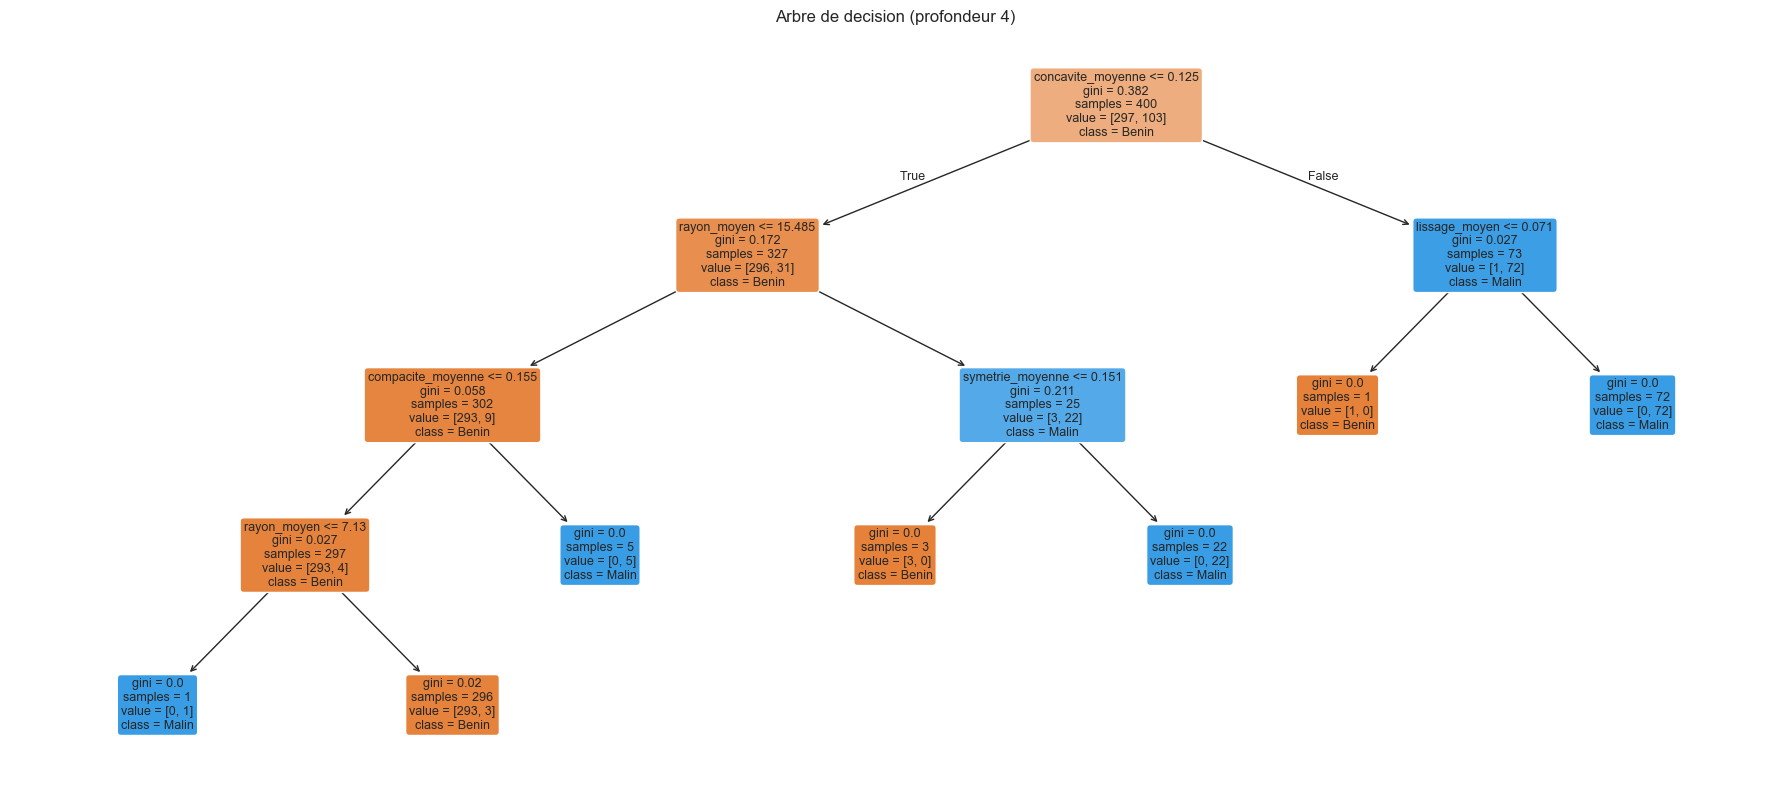

In [18]:
# Visualisation de l'arbre
plt.figure(figsize=(18, 8))
plot_tree(arbre,
          feature_names=features,
          class_names=['Benin', 'Malin'],
          filled=True,
          rounded=True,
          fontsize=9)
plt.title('Arbre de decision (profondeur 4)')
plt.tight_layout()
plt.show()

L'arbre est completement **interpretable** : on peut lire les regles utilisees par le modele pour decider du diagnostic.


---

## 9. Modele 3 -- Random Forest


In [19]:
# Random Forest avec 100 arbres
foret = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
foret.fit(X_train, y_train)

y_pred_rf = foret.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f'Random Forest train : {foret.score(X_train, y_train):.4f}')
print(f'Random Forest test  : {acc_rf:.4f}')
print(f'\nMatrice de confusion :')
print(confusion_matrix(y_test, y_pred_rf))

Random Forest train : 1.0000
Random Forest test  : 0.9700

Matrice de confusion :
[[72  2]
 [ 1 25]]


Importance des variables :
         variable  importance
concavite_moyenne    0.260312
      rayon_moyen    0.182945
  surface_moyenne    0.171936
  perimetre_moyen    0.162275
compacite_moyenne    0.127641
  texture_moyenne    0.037831
    lissage_moyen    0.035058
 symetrie_moyenne    0.022001


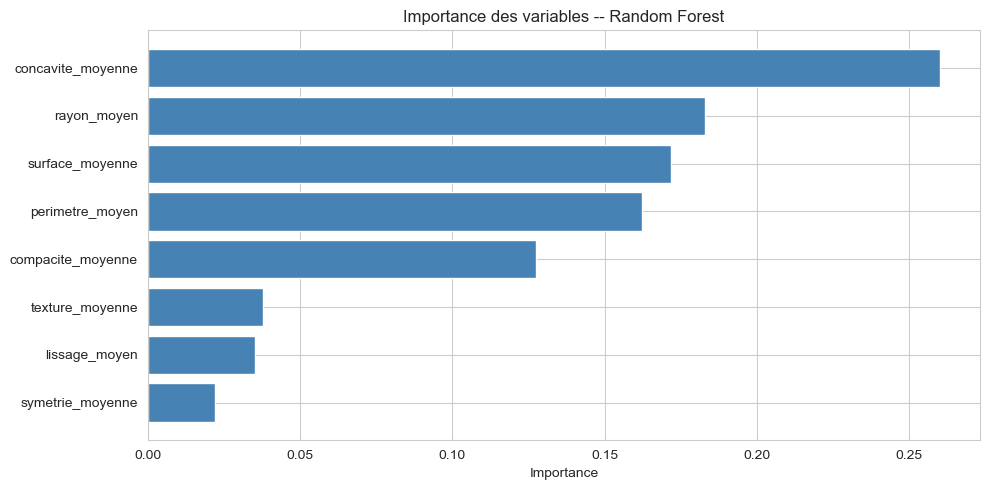

In [20]:
# Importance des variables
importances = pd.DataFrame({
    'variable': features,
    'importance': foret.feature_importances_
}).sort_values('importance', ascending=True)

print('Importance des variables :')
print(importances.iloc[::-1].to_string(index=False))

plt.figure(figsize=(10, 5))
plt.barh(importances['variable'], importances['importance'],
         color='steelblue', edgecolor='white')
plt.xlabel('Importance')
plt.title('Importance des variables -- Random Forest')
plt.tight_layout()
plt.show()

---

## 10. Hyperparameter tuning avec GridSearchCV

Au lieu d'essayer manuellement plusieurs valeurs, on utilise **GridSearchCV** qui teste **toutes les combinaisons** avec validation croisee.


In [ ]:
# Grille d'hyperparametres a explorer
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

print(f'Combinaisons a tester : {3*3*2} = 18')
print(f'Avec CV 5-fold : {18*5} = 90 entrainements')

grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(f'\nMeilleurs parametres : {grid.best_params_}')
print(f'Meilleur score CV    : {grid.best_score_:.4f}')
print(f'\nScore sur le test (modele final) : {grid.score(X_test, y_test):.4f}')

---

## 11. Pipeline scikit-learn -- la protection contre le data leakage

Un **Pipeline** encapsule preprocessing + modele. Quand on l'utilise dans `cross_val_score` ou `GridSearchCV`, **le scaler n'est entraine que sur le train de chaque fold** -- pas de leakage possible.


In [21]:
# Pipeline : StandardScaler + KNN
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Recherche d'hyperparametres avec pipeline
param_grid_pipe = {
    'knn__n_neighbors': [3, 5, 7, 11, 15],
    'knn__weights': ['uniform', 'distance']
}

grid_pipe = GridSearchCV(pipe, param_grid_pipe, cv=5, scoring='accuracy', n_jobs=-1)
grid_pipe.fit(X_train, y_train)

print(f'Meilleurs parametres KNN : {grid_pipe.best_params_}')
print(f'Meilleur score CV       : {grid_pipe.best_score_:.4f}')
print(f'Score sur le test       : {grid_pipe.score(X_test, y_test):.4f}')
print('\nLe pipeline garantit qu\'aucune information du test ne fuite vers le train.')

Meilleurs parametres KNN : {'knn__n_neighbors': 5, 'knn__weights': 'uniform'}
Meilleur score CV       : 0.9675
Score sur le test       : 0.9800

Le pipeline garantit qu'aucune information du test ne fuite vers le train.


---

## 12. Comparaison des 3 modeles supervises


In [22]:
modeles = {
    'KNN (k=5)': (knn, X_train_scaled, X_test_scaled),
    'Arbre (depth=4)': (arbre, X_train, X_test),
    'Random Forest (100)': (foret, X_train, X_test)
}

resultats = []
for nom, (m, Xtr, Xte) in modeles.items():
    acc_train = m.score(Xtr, y_train)
    acc_test = m.score(Xte, y_test)
    y_pred = m.predict(Xte)
    cm = confusion_matrix(y_test, y_pred)
    rappel_m = cm[1, 1] / (cm[1, 0] + cm[1, 1])
    resultats.append({
        'Modele': nom,
        'Train': acc_train,
        'Test': acc_test,
        'Rappel cas malins': rappel_m
    })

comparaison = pd.DataFrame(resultats)
print(comparaison.to_string(index=False))

             Modele  Train  Test  Rappel cas malins
          KNN (k=5) 0.9725  0.98           0.923077
    Arbre (depth=4) 0.9925  0.92           0.923077
Random Forest (100) 1.0000  0.97           0.961538


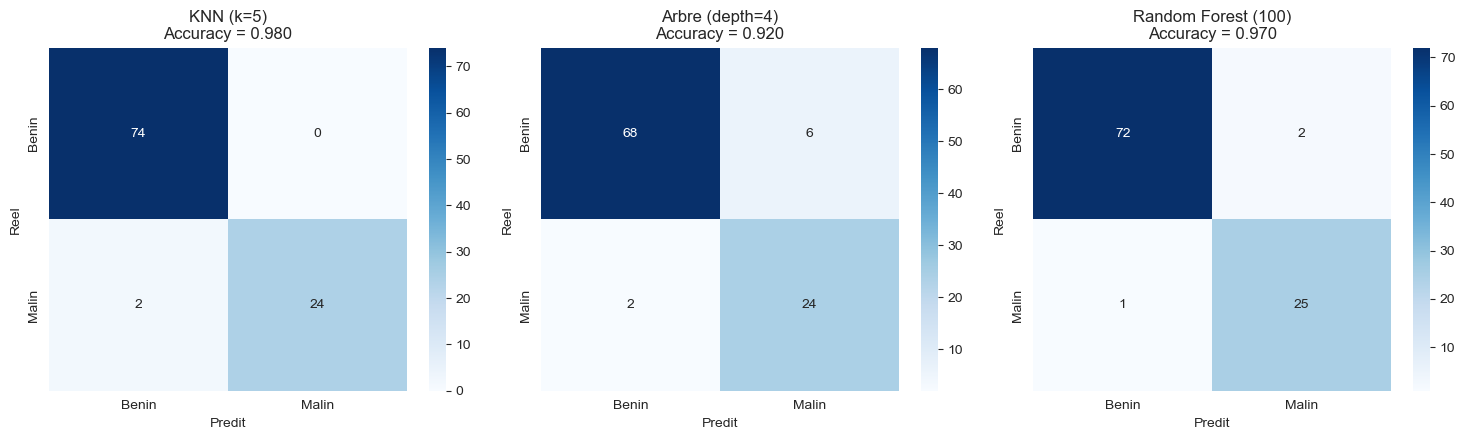

In [23]:
# Matrices de confusion comparees
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nom, (m, _, Xte)) in zip(axes, modeles.items()):
    y_pred = m.predict(Xte)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benin', 'Malin'],
                yticklabels=['Benin', 'Malin'], ax=ax)
    ax.set_title(f'{nom}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}')
    ax.set_xlabel('Predit')
    ax.set_ylabel('Reel')
plt.tight_layout()
plt.show()

---

## 13. Modele 4 -- K-Means (non supervise)

A partir d'ici, on n'utilise plus la cible. On veut voir si l'algorithme peut **decouvrir** la structure du cancer sans supervision.


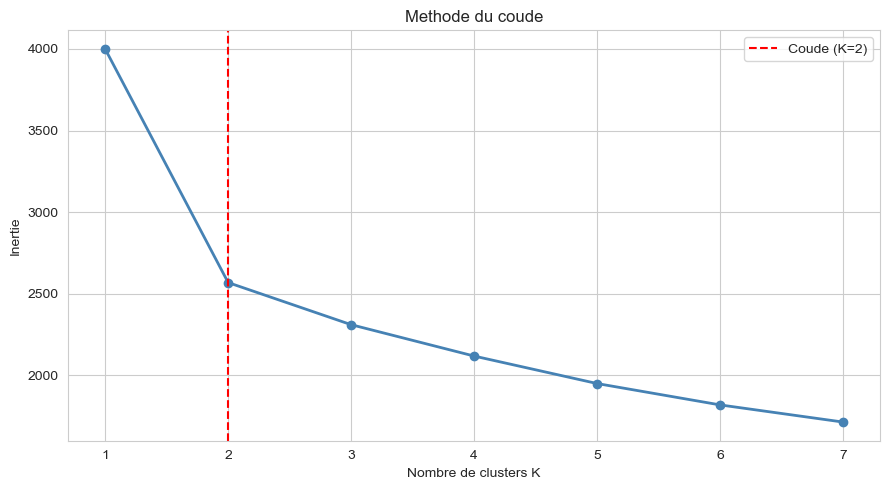

Inerties :
  K=1 : 4000.0
  K=2 : 2568.2
  K=3 : 2310.1
  K=4 : 2117.8
  K=5 : 1949.3
  K=6 : 1818.3
  K=7 : 1713.2


In [31]:
# Standardisation de tout le dataset (clustering = on utilise tout)
X_all_scaled = StandardScaler().fit_transform(X)

# Methode du coude
inerties = []
for k in range(1, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_all_scaled)
    inerties.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(1, 8), inerties, marker='o', linewidth=2, color='steelblue')
plt.xlabel('Nombre de clusters K')
plt.ylabel('Inertie')
plt.title('Methode du coude')
plt.axvline(x=2, color='red', linestyle='--', label='Coude (K=2)')
plt.legend()
plt.tight_layout()
plt.show()

print('Inerties :')
for k, i in zip(range(1, 8), inerties):
    print(f'  K={k} : {i:.1f}')

In [32]:
# K-Means avec K=2
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans.fit(X_all_scaled)

df_clean['cluster_kmeans'] = kmeans.labels_

tab = pd.crosstab(df_clean['cluster_kmeans'],
                  df_clean['diagnostic'],
                  rownames=['Cluster'], colnames=['Diagnostic'])
print('Comparaison clusters K-Means vs diagnostic reel :')
print(tab)

print(f'\nPurete cluster 0 : {tab.iloc[0].max() / tab.iloc[0].sum() * 100:.1f}%')
print(f'Purete cluster 1 : {tab.iloc[1].max() / tab.iloc[1].sum() * 100:.1f}%')

Comparaison clusters K-Means vs diagnostic reel :
Diagnostic    B    M
Cluster             
0           371   23
1             0  106

Purete cluster 0 : 94.2%
Purete cluster 1 : 100.0%


**Resultat remarquable :** K-Means a identifie un cluster **quasi-pur de cas malins** sans avoir vu la cible. C'est la puissance du clustering non supervise pour **decouvrir des structures naturelles**.


---

## 14. Modele 5 -- Clustering hierarchique


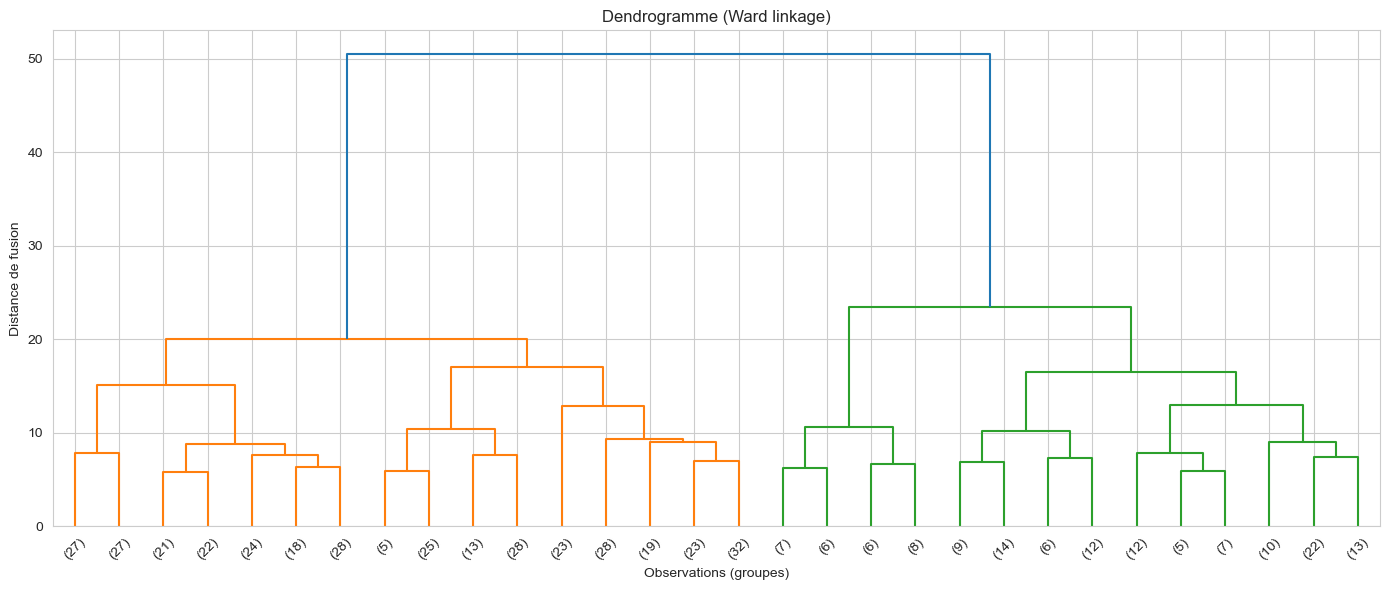

In [29]:
# Dendrogramme (limite a 30 fusions pour la lisibilite)
Z = linkage(X_all_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_font_size=10)
plt.xlabel('Observations (groupes)')
plt.ylabel('Distance de fusion')
plt.title('Dendrogramme (Ward linkage)')
plt.tight_layout()
plt.show()

In [30]:
# AgglomerativeClustering avec K=2
hierarchique = AgglomerativeClustering(n_clusters=2, linkage='ward')
df_clean['cluster_hier'] = hierarchique.fit_predict(X_all_scaled)

tab_hier = pd.crosstab(df_clean['cluster_hier'],
                       df_clean['diagnostic'],
                       rownames=['Cluster'], colnames=['Diagnostic'])
print('Comparaison clusters hierarchique vs diagnostic :')
print(tab_hier)

print(f'\nPurete cluster 0 : {tab_hier.iloc[0].max() / tab_hier.iloc[0].sum() * 100:.1f}%')
print(f'Purete cluster 1 : {tab_hier.iloc[1].max() / tab_hier.iloc[1].sum() * 100:.1f}%')

Comparaison clusters hierarchique vs diagnostic :
Diagnostic    B    M
Cluster             
0            14  123
1           357    6

Purete cluster 0 : 89.8%
Purete cluster 1 : 98.3%


---

## 15. Synthese finale -- comparaison des 5 modeles


In [ ]:
synthese = pd.DataFrame({
    'Modele': ['KNN (k=5)', 'Arbre (depth=4)', 'Random Forest', 'K-Means (K=2)', 'Hierarchique (K=2)'],
    'Type': ['Supervise', 'Supervise', 'Supervise', 'Non supervise', 'Non supervise'],
    'Accuracy test': [f'{acc_knn:.3f}', f'{acc_arbre:.3f}', f'{acc_rf:.3f}', 'N/A', 'N/A'],
    'Interpretable': ['Non', 'Oui (arbre)', 'Variables imp.', 'Centroides', 'Dendrogramme'],
    'Standardisation': ['Obligatoire', 'Non requise', 'Non requise', 'Obligatoire', 'Obligatoire'],
})
print(synthese.to_string(index=False))

## 16. Conclusions

Ce notebook a couvert l'ensemble de la chaine du Machine Learning sur un cas concret :

### Sur les concepts fondamentaux :
- **Types de donnees et de problemes** (classification binaire, variables numeriques)
- **Encodage** : Label Encoding (cible binaire, ordinales) vs One-Hot Encoding (nominales)
- **Mise a l'echelle** : StandardScaler par defaut, MinMaxScaler pour cas specifiques
- **Train/test split** avec stratification pour preserver les proportions
- **Validation croisee** pour une evaluation robuste
- **Hyperparameter tuning** automatique avec GridSearchCV
- **Pipeline** pour eviter le data leakage

### Sur les modeles :
- **Supervise** : KNN, Arbre, Random Forest. Random Forest combine performance et interpretabilite (importance des variables).
- **Non supervise** : K-Means et Clustering hierarchique. Tous les deux ont "decouvert" la structure du cancer sans supervision.

### Lecons cles :
1. **Il n'existe pas un meilleur modele universel** : le choix depend du probleme (cible disponible ou non), des contraintes (interpretabilite, vitesse), des caracteristiques des donnees.
2. **La preparation des donnees represente ~70% du travail** : encodage, mise a l'echelle, traitement des NaN sont essentiels.
3. **Toujours valider rigoureusement** : train/test + validation croisee + matrice de confusion (pas seulement l'accuracy).
4. **Eviter le data leakage** : Pipeline est votre meilleur ami.

La prochaine seance abordera le **Deep Learning** : reseaux de neurones capables de capturer des patterns encore plus complexes, au prix d'une perte d'interpretabilite et d'un besoin en donnees beaucoup plus grand.
